In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import root_mean_squared_error

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor, early_stopping, log_evaluation

RANDOM_STATE = 42
N_FOLDS = 5
print('Libraries loaded successfully')

Libraries loaded successfully


In [2]:
#2
train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv',
                    low_memory=False)
test  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv',
                    low_memory=False)

print('Train shape:', train.shape)
print('Test shape :', test.shape)
train.head(3)

Train shape: (138701, 50)
Test shape : (15000, 49)


,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


In [3]:
#3 Basic Overview 
print('dtypes:\n', train.dtypes.value_counts())
print('\nTarget stats:')
print(train['TargetValue'].describe())

dtypes:
 object     44
int64       4
float64     2
Name: count, dtype: int64

Target stats:
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64


In [4]:
#4 missing value analysis
missing_pct = train.isnull().mean().sort_values(ascending=False)
missing_df = missing_pct[missing_pct > 0].reset_index()
missing_df.columns = ['Column', 'Missing%']
print(f'{len(missing_df)} columns have missing values')
display(missing_df.head(25))

35 columns have missing values


,Column,Missing%
0,col19,0.999524
1,col18,0.999524
2,col5,0.925156
3,col4,0.925156
4,col27,0.892149
5,col28,0.892149
6,col29,0.863938
7,col30,0.863938
8,col13,0.831256
9,col14,0.831256


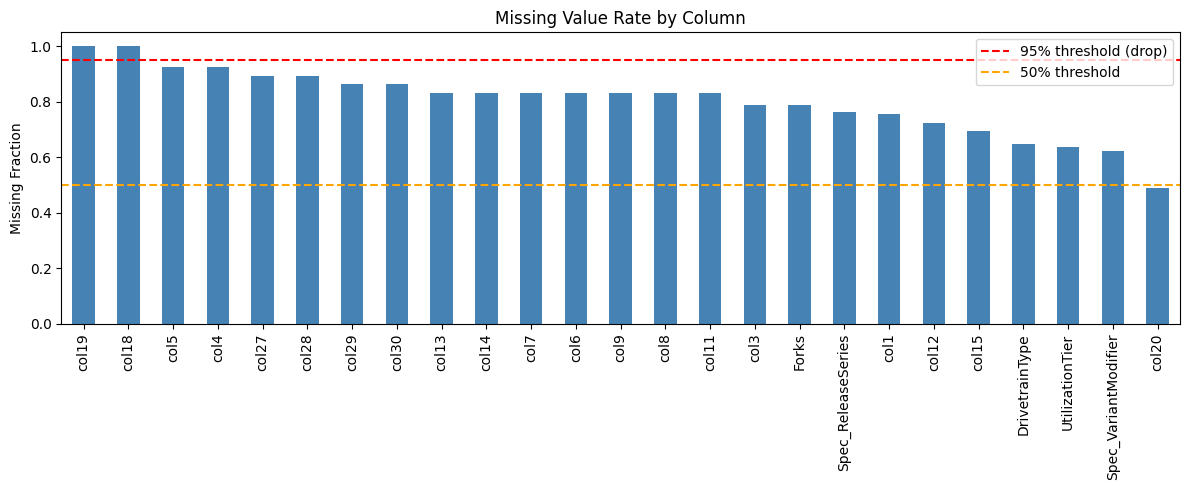

In [5]:
#5. missing value visualisations
fig, ax = plt.subplots(figsize=(12, 5))
top_missing = missing_pct[missing_pct > 0].head(25)
top_missing.plot(kind='bar', ax=ax, color='steelblue')
ax.axhline(0.95, color='red', linestyle='--', label='95% threshold (drop)')
ax.axhline(0.5,  color='orange', linestyle='--', label='50% threshold')
ax.set_title('Missing Value Rate by Column')
ax.set_ylabel('Missing Fraction')
ax.legend()
plt.tight_layout()
plt.show()


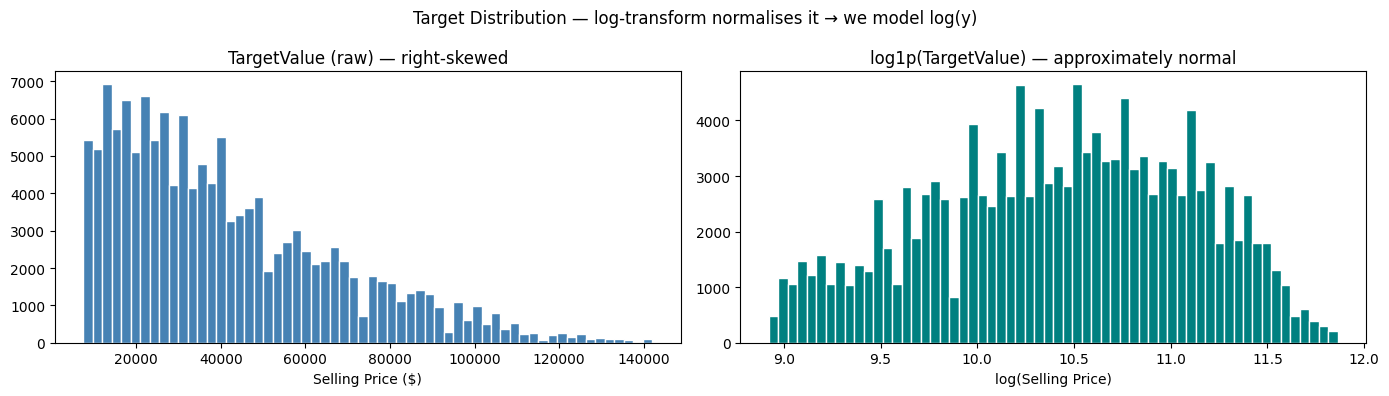

In [6]:
#6. target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(train['TargetValue'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('TargetValue (raw) — right-skewed')
axes[0].set_xlabel('Selling Price ($)')

axes[1].hist(np.log1p(train['TargetValue']), bins=60, color='teal', edgecolor='white')
axes[1].set_title('log1p(TargetValue) — approximately normal')
axes[1].set_xlabel('log(Selling Price)')

plt.suptitle('Target Distribution — log-transform normalises it → we model log(y)', fontsize=12)
plt.tight_layout()
plt.show()


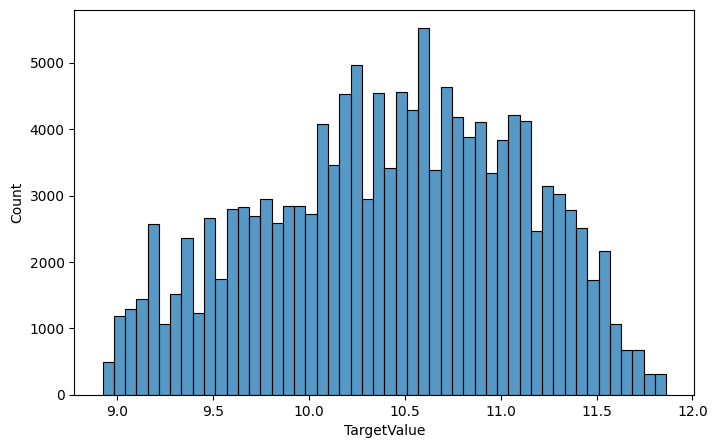

In [7]:
#7. target distribution (log-transformed)
plt.figure(figsize=(8,5))
sns.histplot(np.log1p(train["TargetValue"]), bins=50)
plt.show()

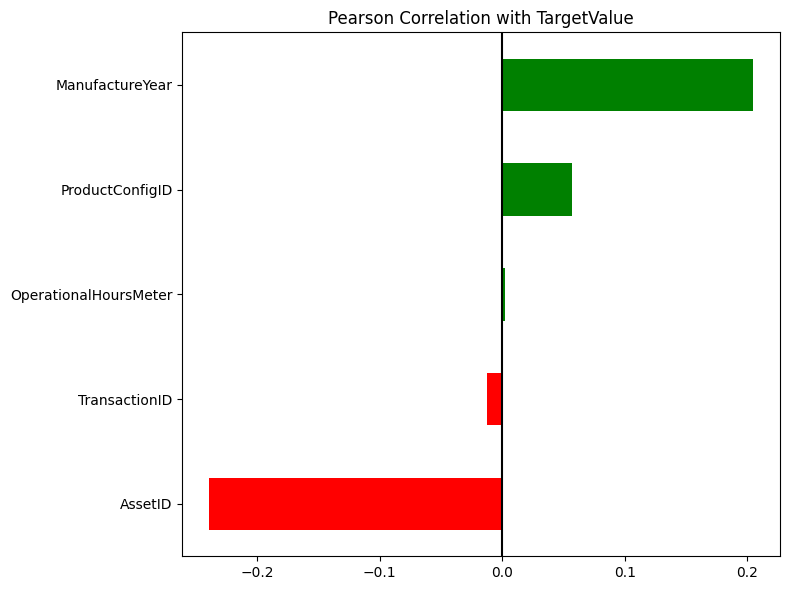


Top positive correlators:
AssetID                 -0.238719
TransactionID           -0.012093
OperationalHoursMeter    0.001994
ProductConfigID          0.057265
ManufactureYear          0.204439
Name: TargetValue, dtype: float64

Top negative correlators:
AssetID                 -0.238719
TransactionID           -0.012093
OperationalHoursMeter    0.001994
ProductConfigID          0.057265
ManufactureYear          0.204439
Name: TargetValue, dtype: float64


In [8]:
#8. Numerical Stats
num_cols_raw = train.select_dtypes(include='number').columns.tolist()
corr = train[num_cols_raw].corr()['TargetValue'].drop('TargetValue').sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
corr.plot(kind='barh', ax=ax, color=['red' if v < 0 else 'green' for v in corr])
ax.set_title('Pearson Correlation with TargetValue')
ax.axvline(0, color='black')
plt.tight_layout()
plt.show()
print('\nTop positive correlators:')
print(corr.tail(5))
print('\nTop negative correlators:')
print(corr.head(5))

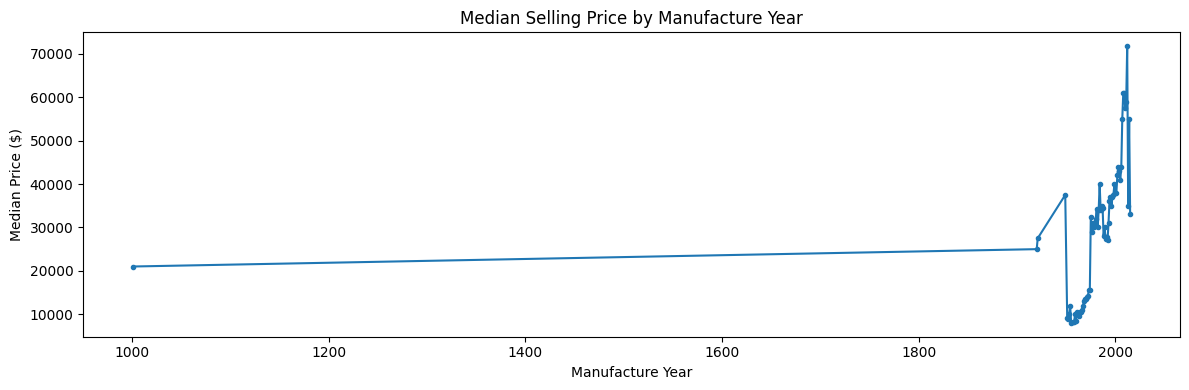

In [9]:
#9 ManufactureYear vs Price
train_tmp = train.copy()
train_tmp['ManufactureYear'] = pd.to_numeric(train_tmp['ManufactureYear'], errors='coerce')
year_price = train_tmp.groupby('ManufactureYear')['TargetValue'].median().reset_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(year_price['ManufactureYear'], year_price['TargetValue'], marker='o', markersize=3)
ax.set_title('Median Selling Price by Manufacture Year')
ax.set_xlabel('Manufacture Year')
ax.set_ylabel('Median Price ($)')
plt.tight_layout()
plt.show()

In [10]:
#10. Region Analysis
region_stats = (
    train.groupby(
        "RegionCode"
    )["TargetValue"]
    .mean()
    .sort_values(
        ascending=False
    )
)

display(
    region_stats.head(20)
)

RegionCode
South Dakota     54628.455285
Rhode Island     52992.857143
Unspecified      51705.631399
Nevada           47533.589744
Alabama          47471.214343
North Dakota     46017.015707
West Virginia    45270.577933
Florida          45007.542626
Mississippi      44990.111190
Georgia          44501.412214
Texas            44341.440713
Arizona          43524.403611
Nebraska         43438.772846
New Mexico       43424.448529
Colorado         43261.847581
Montana          42987.826962
Oklahoma         41764.013841
Iowa             41507.443366
Kentucky         41375.221239
Utah             41220.520422
Name: TargetValue, dtype: float64

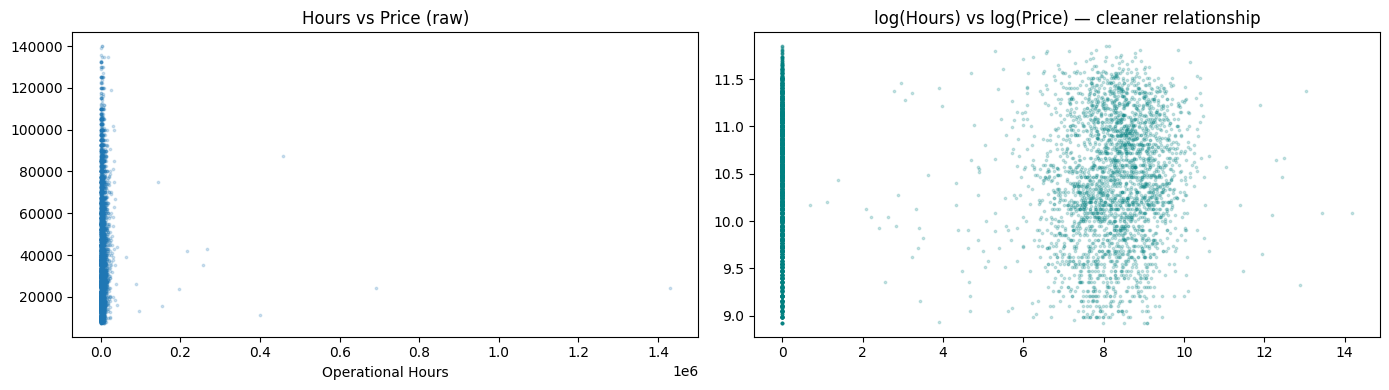

Correlation (raw): -0.004 | Correlation (log-log): 0.005


In [11]:
#11 OperationalHoursMeter vs Price
sample = train.sample(min(8000, len(train)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(sample['OperationalHoursMeter'], sample['TargetValue'], alpha=0.2, s=3)
axes[0].set_title('Hours vs Price (raw)')
axes[0].set_xlabel('Operational Hours')
axes[1].scatter(np.log1p(sample['OperationalHoursMeter'].fillna(0)),
                np.log1p(sample['TargetValue']), alpha=0.2, s=3, color='teal')
axes[1].set_title('log(Hours) vs log(Price) — cleaner relationship')
plt.tight_layout()
plt.show()
corr_raw = sample['OperationalHoursMeter'].corr(sample['TargetValue'])
corr_log = np.log1p(sample['OperationalHoursMeter'].fillna(0)).corr(np.log1p(sample['TargetValue']))
print(f'Correlation (raw): {corr_raw:.3f} | Correlation (log-log): {corr_log:.3f}')


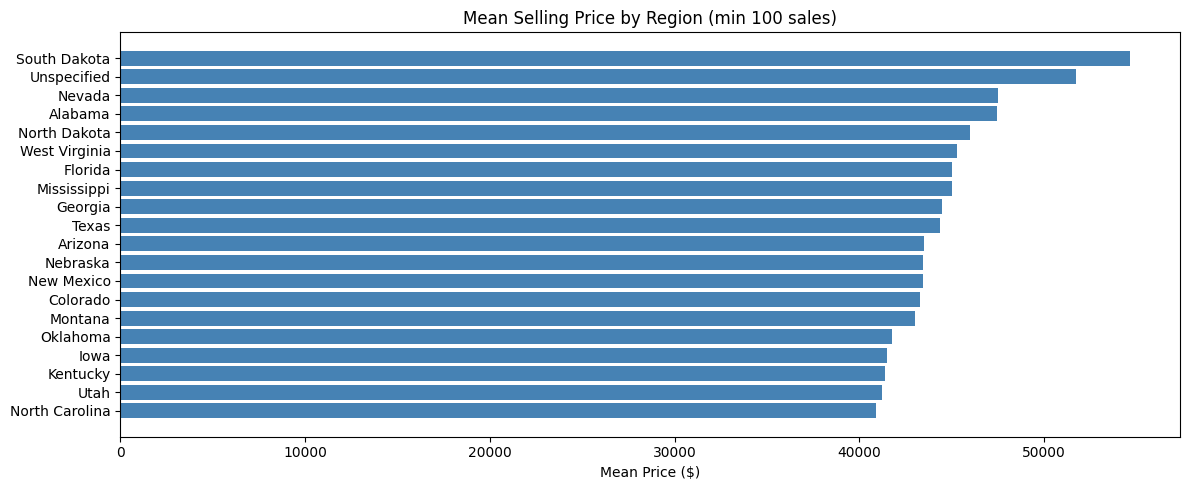

Region with highest avg price: South Dakota


In [12]:
#12. Region Analysis Visualisation
region_stats = train.groupby('RegionCode')['TargetValue'].agg(['mean','count']).sort_values('mean', ascending=False)
top_regions = region_stats[region_stats['count'] > 100].head(20)

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(top_regions.index[::-1], top_regions['mean'][::-1], color='steelblue')
ax.set_title('Mean Selling Price by Region (min 100 sales)')
ax.set_xlabel('Mean Price ($)')
plt.tight_layout()
plt.show()
print('Region with highest avg price:', top_regions.index[0])

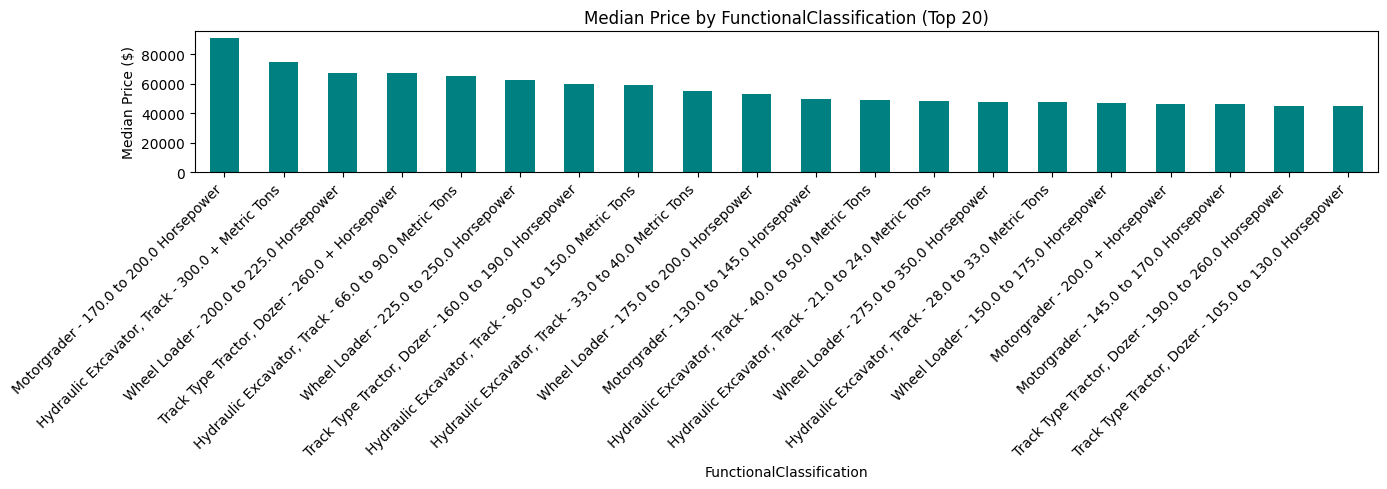

In [13]:
#13. Functional Classification
fc_stats = train.groupby('FunctionalClassification')['TargetValue'].median().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 5))
fc_stats.head(20).plot(kind='bar', ax=ax, color='teal')
ax.set_title('Median Price by FunctionalClassification (Top 20)')
ax.set_ylabel('Median Price ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Utilization Tier price medians:


,median,count
UtilizationTier,,
High,47000.0,8882
Low,24000.0,17005
Medium,37000.0,24588


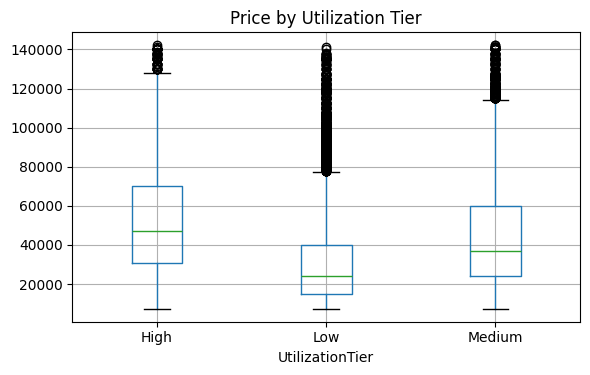

In [14]:
#14. Utilisation Tier
ut_stats = train.groupby('UtilizationTier')['TargetValue'].agg(['median','count'])
print('Utilization Tier price medians:')
display(ut_stats)

fig, ax = plt.subplots(figsize=(6, 4))
train.boxplot(column='TargetValue', by='UtilizationTier', ax=ax)
ax.set_title('Price by Utilization Tier')
plt.suptitle('')
plt.tight_layout()
plt.show()

In [15]:
#15. Preprocessing and Feature engineering
# Reload clean copies
train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv',
                    low_memory=False)
test  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv',
                    low_memory=False)

def engineer_features(df, ref_df=None):
    """
    Apply all feature engineering steps.
    ref_df: reference dataframe for frequency encoding (use train for test set).
    All transformations applied identically to train and test (no leakage).
    """
    df = df.copy()
    ref = ref_df if ref_df is not None else df

    # Date features 
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])
    df['TxYear']  = df['TransactionDate'].dt.year
    df['TxMonth'] = df['TransactionDate'].dt.month
    df['TxQuarter'] = df['TransactionDate'].dt.quarter

    # Asset Age (clip outliers) 
    df['ManufactureYear'] = pd.to_numeric(df['ManufactureYear'], errors='coerce')
    df['AssetAge'] = (df['TxYear'] - df['ManufactureYear']).clip(0, 60)
    df['AgeSq'] = df['AssetAge'] ** 2  # non-linear depreciation

    # Operational Hours (log-transform, ratio feature) 
    df['LogHours'] = np.log1p(df['OperationalHoursMeter'])
    df['HoursPerYear'] = df['OperationalHoursMeter'] / (df['AssetAge'] + 1)
    df['LogHoursPerYear'] = np.log1p(df['HoursPerYear'])

    # Interaction: age × usage 
    df['Age_x_LogHours'] = df['AssetAge'] * df['LogHours']

    # Missingness flags for informative missing cols
    for col in ['OperationalHoursMeter', 'UtilizationTier', 'CabinType', 'DrivetrainType']:
        if col in df.columns:
            df[col + '_miss'] = df[col].isnull().astype(np.int8)

    # Frequency encoding (high-cardinality categoricals) 
    for col in ['ProductConfigID', 'Spec_BaseClass', 'RegionCode',
                'FunctionalClassification', 'Spec_SubClass',
                'InventoryGroupCategory', 'VendorPartnerID']:
        if col in df.columns:
            freq = ref[col].value_counts()
            df[col + '_freq'] = df[col].map(freq).fillna(0).astype(np.float32)

    return df

train = engineer_features(train)
test  = engineer_features(test, ref_df=train)

print('After FE — train:', train.shape, '| test:', test.shape)

After FE — train: (138701, 70) | test: (15000, 69)


In [16]:
#16. Drop columns with >95% missing (no signal)
drop_95 = [c for c in train.columns
           if train[c].isnull().mean() > 0.95 and c != 'TargetValue']
print(f'Dropping {len(drop_95)} near-empty columns:', drop_95)

train.drop(columns=drop_95, inplace=True)
test.drop(columns=drop_95, errors='ignore', inplace=True)

Dropping 2 near-empty columns: ['col18', 'col19']


In [17]:
#17. Out-of-Fold Target Encoding for high-cardinality columns
# OOF encoding prevents target leakage: validation fold stats never see training fold labels.

TARGET_COL = 'TargetValue'
y_log = np.log1p(train[TARGET_COL])
GLOBAL_MEAN = y_log.mean()
SMOOTH = 20  # smoothing factor: higher = more shrinkage toward global mean

kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

TE_COLS = ['ProductConfigID', 'Spec_BaseClass', 'FunctionalClassification', 'Spec_SubClass']
TE_COLS = [c for c in TE_COLS if c in train.columns]

for col in TE_COLS:
    oof_te   = np.zeros(len(train))
    test_enc = np.zeros(len(test))

    for tr_idx, val_idx in kf.split(train):
        # Compute smoothed mean on training fold
        stats = y_log.iloc[tr_idx].groupby(train[col].iloc[tr_idx]).agg(['sum', 'count'])
        stats['enc'] = (stats['sum'] + SMOOTH * GLOBAL_MEAN) / (stats['count'] + SMOOTH)
        oof_te[val_idx] = train[col].iloc[val_idx].map(stats['enc']).fillna(GLOBAL_MEAN).values

    # For test: use full training set
    stats_full = y_log.groupby(train[col]).agg(['sum', 'count'])
    stats_full['enc'] = (stats_full['sum'] + SMOOTH * GLOBAL_MEAN) / (stats_full['count'] + SMOOTH)
    test_enc = test[col].map(stats_full['enc']).fillna(GLOBAL_MEAN).values

    train[col + '_te'] = oof_te
    test[col  + '_te'] = test_enc
    print(f'Target-encoded: {col}')

print('OOF target encoding complete.')

Target-encoded: ProductConfigID
Target-encoded: Spec_BaseClass
Target-encoded: FunctionalClassification
Target-encoded: Spec_SubClass
OOF target encoding complete.


In [18]:
#18. Build X / y 
DROP_IDS = ['TransactionID', 'AssetID', 'TransactionDate', 'TargetValue']
X = train.drop(columns=[c for c in DROP_IDS if c in train.columns])
y = y_log.values
X_test = test.drop(columns=[c for c in DROP_IDS if c in test.columns], errors='ignore')

# Identify column types
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f'Numeric: {len(num_cols)} | Categorical: {len(cat_cols)} | Total: {X.shape[1]}')

# Encode categoricals (OrdinalEncoder + median impute numerics)
for c in cat_cols:
    X[c]      = X[c].astype(str).replace('nan', '__NA__')
    X_test[c] = X_test[c].astype(str).replace('nan', '__NA__')

enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X[cat_cols]      = enc.fit_transform(X[cat_cols]).astype(np.float32)
X_test[cat_cols] = enc.transform(X_test[cat_cols]).astype(np.float32)

medians = X[num_cols].median()
X[num_cols]      = X[num_cols].fillna(medians).astype(np.float32)
X_test[num_cols] = X_test[num_cols].fillna(medians).astype(np.float32)

print('Preprocessing done. X shape:', X.shape)

Numeric: 27 | Categorical: 41 | Total: 68
Preprocessing done. X shape: (138701, 68)


In [19]:
#19. Model: 1 (Dummy Baseline)
# Baseline: always predict median log-price
dummy_pred = np.full(len(y), np.median(y))
dummy_rmsle = root_mean_squared_error(y, dummy_pred)
print(f'Dummy (median) RMSLE: {dummy_rmsle:.4f}')


Dummy (median) RMSLE: 0.6721


In [20]:
#20. Model: 2
# Random Forest 
rf_oof = np.zeros(len(y))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X)):
    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
    rf.fit(X.iloc[tr_idx], y[tr_idx])
    rf_oof[val_idx] = rf.predict(X.iloc[val_idx])
    fold_rmsle = root_mean_squared_error(y[val_idx], rf_oof[val_idx])
    print(f'  RF fold {fold}: RMSLE = {fold_rmsle:.4f}')

rf_rmsle = root_mean_squared_error(y, rf_oof)
print(f'\nRandom Forest OOF RMSLE: {rf_rmsle:.4f}')

  RF fold 0: RMSLE = 0.2182
  RF fold 1: RMSLE = 0.2200
  RF fold 2: RMSLE = 0.2194
  RF fold 3: RMSLE = 0.2219
  RF fold 4: RMSLE = 0.2182

Random Forest OOF RMSLE: 0.2196


In [21]:
#21. Model: 3
# LightGBM — gradient boosting, handles high-cardinality well, fast
# Using early stopping to find optimal number of trees per fold

LGB_PARAMS = dict(
    n_estimators    = 10000,   # high ceiling; early stopping controls actual count
    learning_rate   = 0.02,
    num_leaves      = 200,     # more leaves = more complex model
    subsample       = 0.8,     # row subsampling per tree
    subsample_freq  = 1,
    colsample_bytree= 0.7,     # feature subsampling per tree
    min_child_samples = 15,
    reg_alpha       = 0.05,    # L1 regularisation
    reg_lambda      = 0.05,    # L2 regularisation
    random_state    = RANDOM_STATE,
    n_jobs          = -1,
    verbose         = -1
)

lgb_oof  = np.zeros(len(y))
lgb_test = np.zeros(len(X_test))
best_iters = []

for fold, (tr_idx, val_idx) in enumerate(kf.split(X)):
    Xtr, Xval = X.iloc[tr_idx], X.iloc[val_idx]
    ytr, yval = y[tr_idx],      y[val_idx]

    model = LGBMRegressor(**LGB_PARAMS)
    model.fit(
        Xtr, ytr,
        eval_set=[(Xval, yval)],
        callbacks=[
            early_stopping(stopping_rounds=100, verbose=False),
            log_evaluation(500)
        ]
    )

    lgb_oof[val_idx]  = model.predict(Xval)
    lgb_test         += model.predict(X_test) / N_FOLDS
    best_iters.append(model.best_iteration_)

    fold_rmsle = root_mean_squared_error(yval, lgb_oof[val_idx])
    print(f'  LGB fold {fold}: RMSLE = {fold_rmsle:.4f}  (best iter = {model.best_iteration_})')

lgb_rmsle = root_mean_squared_error(y, lgb_oof)
print(f'\nLightGBM OOF RMSLE: {lgb_rmsle:.4f}')
print(f'Avg best iterations: {np.mean(best_iters):.0f}')

[500]	valid_0's l2: 0.0424854
[1000]	valid_0's l2: 0.0404794
[1500]	valid_0's l2: 0.0396595
[2000]	valid_0's l2: 0.03923
[2500]	valid_0's l2: 0.0389623
[3000]	valid_0's l2: 0.0387793
[3500]	valid_0's l2: 0.0386563
[4000]	valid_0's l2: 0.038593
[4500]	valid_0's l2: 0.0385414
  LGB fold 0: RMSLE = 0.1963  (best iter = 4482)
[500]	valid_0's l2: 0.0438401
[1000]	valid_0's l2: 0.0417004
[1500]	valid_0's l2: 0.0408319
[2000]	valid_0's l2: 0.0403429
[2500]	valid_0's l2: 0.0399659
[3000]	valid_0's l2: 0.0397532
[3500]	valid_0's l2: 0.0395792
[4000]	valid_0's l2: 0.0394617
[4500]	valid_0's l2: 0.0393725
[5000]	valid_0's l2: 0.0393146
[5500]	valid_0's l2: 0.039287
  LGB fold 1: RMSLE = 0.1982  (best iter = 5711)
[500]	valid_0's l2: 0.0437348
[1000]	valid_0's l2: 0.0415998
[1500]	valid_0's l2: 0.0407889
[2000]	valid_0's l2: 0.0403386
[2500]	valid_0's l2: 0.0400166
[3000]	valid_0's l2: 0.0398288
[3500]	valid_0's l2: 0.039672
[4000]	valid_0's l2: 0.0395708
[4500]	valid_0's l2: 0.0395028
  LGB fold 

,Model,OOF RMSLE
2,LightGBM (+ Target Encoding),0.197977
1,Random Forest,0.219550
0,Dummy (Median),0.672093


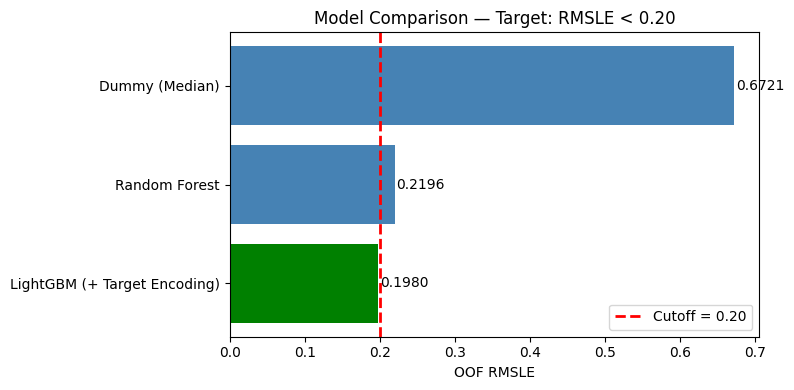

In [22]:
#22. Model Comparison
results = pd.DataFrame({
    'Model':   ['Dummy (Median)', 'Random Forest', 'LightGBM (+ Target Encoding)'],
    'OOF RMSLE': [dummy_rmsle, rf_rmsle, lgb_rmsle]
}).sort_values('OOF RMSLE')

display(results)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['steelblue', 'orange', 'green']
bars = ax.barh(results['Model'], results['OOF RMSLE'],
               color=['green' if v < 0.20 else 'steelblue' for v in results['OOF RMSLE']])
ax.axvline(0.20, color='red', linestyle='--', linewidth=2, label='Cutoff = 0.20')
ax.set_xlabel('OOF RMSLE')
ax.set_title('Model Comparison — Target: RMSLE < 0.20')
ax.legend()
for bar, val in zip(bars, results['OOF RMSLE']):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()

print()


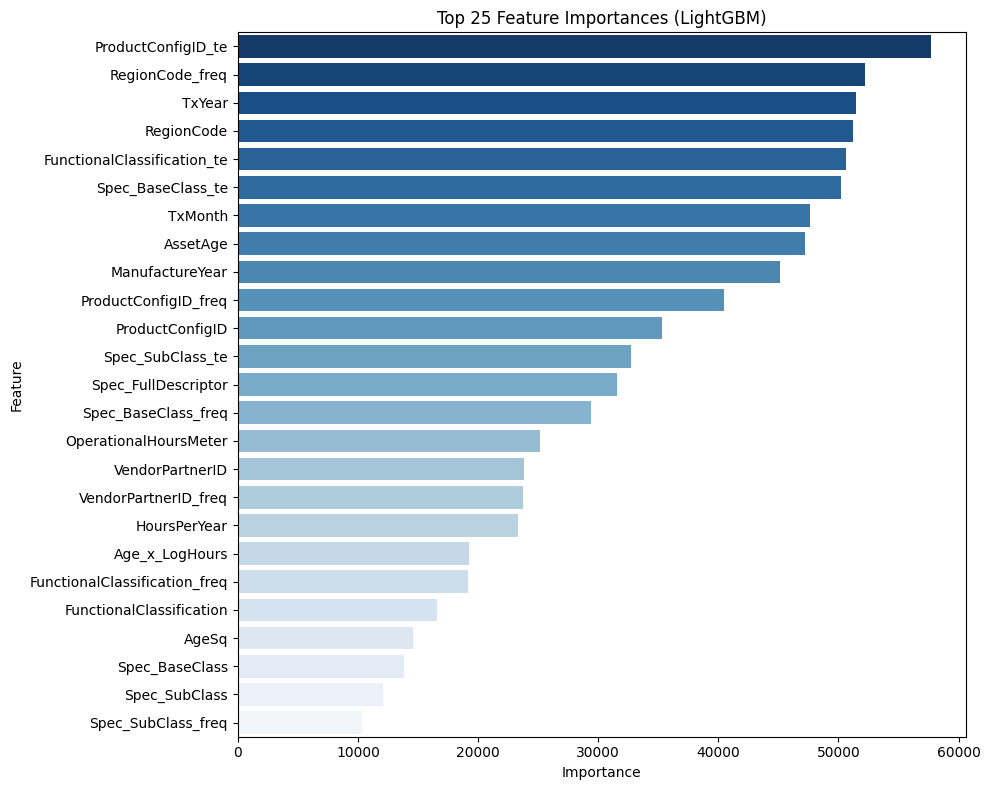


Top 10 features:


,Feature,Importance
64,ProductConfigID_te,57729
59,RegionCode_freq,52250
44,TxYear,51427
13,RegionCode,51217
66,FunctionalClassification_te,50631
65,Spec_BaseClass_te,50191
45,TxMonth,47649
47,AssetAge,47188
3,ManufactureYear,45177
57,ProductConfigID_freq,40510


In [23]:
#22. feature importance analysis
# Retrain final LGB on full data to get feature importances
avg_iters = int(np.mean(best_iters))
final_model = LGBMRegressor(**{**LGB_PARAMS, 'n_estimators': avg_iters})
final_model.fit(X, y)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': final_model.feature_importances_
}).sort_values('Importance', ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=importance_df.head(25), x='Importance', y='Feature', ax=ax, palette='Blues_r')
ax.set_title('Top 25 Feature Importances (LightGBM)')
plt.tight_layout()
plt.show()

print('\nTop 10 features:')
display(importance_df.head(10))

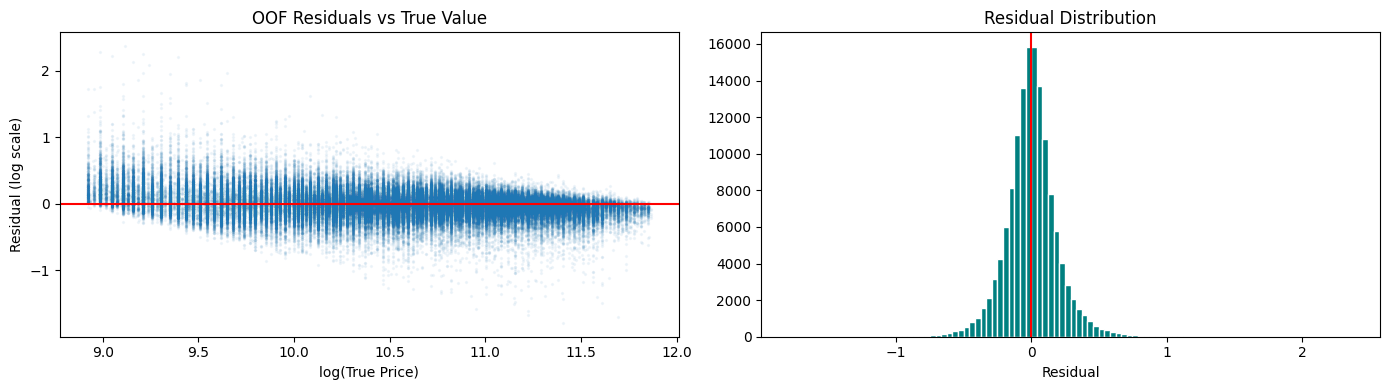


Worst 10 predictions (largest RMSLE per sample):


,TargetValue,oof_pred_log,abs_residual,FunctionalClassification,AssetAge,LogHours
41946,9100.0,11.485190,2.369051,"Track Type Tractor, Dozer - 160.0 to 190.0 Hor...",3,NaN
30470,8000.0,11.272088,2.284766,"Hydraulic Excavator, Track - 33.0 to 40.0 Metr...",6,NaN
21266,10000.0,11.459864,2.249423,"Hydraulic Excavator, Track - 28.0 to 33.0 Metr...",4,NaN
79081,8500.0,11.267953,2.220014,Wheel Loader - 200.0 to 225.0 Horsepower,11,0.000000
30067,12000.0,11.591598,2.198853,"Hydraulic Excavator, Track - 33.0 to 40.0 Metr...",3,NaN
37385,9500.0,11.293214,2.134062,Wheel Loader - 200.0 to 225.0 Horsepower,4,NaN
60154,10300.0,11.330183,2.090187,"Hydraulic Excavator, Track - 50.0 to 66.0 Metr...",6,NaN
30770,10000.0,11.183093,1.972653,"Hydraulic Excavator, Track - 50.0 to 66.0 Metr...",9,NaN
23533,15500.0,11.613318,1.964658,"Track Type Tractor, Dozer - 160.0 to 190.0 Hor...",1,NaN
71328,11500.0,11.300776,1.950586,"Hydraulic Excavator, Track - 33.0 to 40.0 Metr...",3,7.909489


In [24]:
#23. Error Analysis
# Residual analysis on OOF predictions
residuals = lgb_oof - y  # in log space

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(y, residuals, alpha=0.05, s=2)
axes[0].axhline(0, color='red')
axes[0].set_xlabel('log(True Price)')
axes[0].set_ylabel('Residual (log scale)')
axes[0].set_title('OOF Residuals vs True Value')

axes[1].hist(residuals, bins=100, color='teal', edgecolor='white')
axes[1].axvline(0, color='red')
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual')
plt.tight_layout()
plt.show()

# Large-error samples
train_copy = train.copy()
train_copy['oof_pred_log'] = lgb_oof
train_copy['abs_residual'] = np.abs(residuals)
print('\nWorst 10 predictions (largest RMSLE per sample):')
display(train_copy.nlargest(10, 'abs_residual')[['TargetValue', 'oof_pred_log', 'abs_residual',
                                                   'FunctionalClassification', 'AssetAge', 'LogHours']].head(10))


In [25]:
#24. Submission
# LightGBM OOF-averaged predictions on test set
test_preds = np.expm1(lgb_test)  # inverse log1p to get back to dollar scale
test_preds = np.maximum(test_preds, 0)  # no negative prices

# Load original test to get TransactionID
test_raw = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv',
                       usecols=['TransactionID'])

submission = pd.DataFrame({
    'TransactionID': test_raw['TransactionID'],
    'TargetValue':   np.round(test_preds, 1)
})

submission.to_csv('submission.csv', index=False)
print('Saved submission.csv')
print(f'Predictions shape: {submission.shape}')
print(f'Price range: ${submission.TargetValue.min():.0f} – ${submission.TargetValue.max():.0f}')
submission.head(10)

Saved submission.csv
Predictions shape: (15000, 2)
Price range: $7476 – $141818


,TransactionID,TargetValue
0,1139307,69005.7
1,1139419,77465.1
2,1139482,31508.6
3,1139522,19117.9
4,1139684,13545.4
5,1139773,28675.1
6,1139779,20206.9
7,1139793,43951.0
8,1139814,75147.5
9,1139839,14562.1


# Milestones


In [26]:
import os, glob, re
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 100)
np.random.seed(42)

def find_file(fname):
    candidates = [fname, os.path.join('.', fname)]
    for c in candidates:
        if os.path.exists(c):
            return c
    matches = glob.glob(f'/kaggle/input/**/{fname}', recursive=True)
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Could not locate {fname}. Place it next to the notebook "
                             f"or update find_file().")

TRAIN_PATH = find_file('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
TEST_PATH  = find_file('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')
print('Using train:', TRAIN_PATH)
print('Using test :', TEST_PATH)


Using train: /kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
Using test : /kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# Milestone 1 — Basic Dataset Understanding, Missing Values, Target & Categorical Profiling

In [27]:
train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)
print('train shape:', train.shape)
print('test shape :', test.shape)

train shape: (138701, 50)
test shape : (15000, 49)


**Q1. Number of records in train.csv and test.csv**

In [28]:
n_train_rows = train.shape[0]
n_test_rows  = test.shape[0]
print(f'train.csv rows: {n_train_rows}')
print(f'test.csv rows : {n_test_rows}')

train.csv rows: 138701
test.csv rows : 15000


**Q2. Target variable = strict set difference between train and test columns**

In [29]:
target_col = list(set(train.columns) - set(test.columns))
print('Target variable(s):', target_col)

Target variable(s): ['TargetValue']


**Q3. Number of columns strictly numerical (int64 / float64) in train**

In [30]:
numeric_cols_m1 = train.select_dtypes(include=['int64', 'float64']).columns.tolist()
print('Number of numeric columns:', len(numeric_cols_m1))
print(numeric_cols_m1)

Number of numeric columns: 6
['TransactionID', 'TargetValue', 'AssetID', 'ProductConfigID', 'ManufactureYear', 'OperationalHoursMeter']


**Q4. Columns with >90% missing values (i.e. missing more than 124,800 of 138,701 rows)**

In [31]:
missing_counts = train.isna().sum()
threshold = 0.90 * len(train)
high_missing_cols = missing_counts[missing_counts > threshold].sort_values(ascending=False)
print(f'Threshold rows: {threshold:.0f}')
print(high_missing_cols)

Threshold rows: 124831
col19    138635
col18    138635
col5     128320
col4     128320
dtype: int64


**Q5. Approximate % missing values for `OperationalHoursMeter`**

In [32]:
pct_missing_ohm = train['OperationalHoursMeter'].isna().mean() * 100
print(f'% missing OperationalHoursMeter: {pct_missing_ohm:.2f}%')

% missing OperationalHoursMeter: 40.84%


**Q6. Median `TargetValue`**

In [33]:
median_target = train['TargetValue'].median()
print('Median TargetValue:', median_target)

Median TargetValue: 35000.0


**Q7. Mode (most frequent) `ManufactureYear`**

In [34]:
mode_manu_year = train['ManufactureYear'].mode()[0]
print('Mode ManufactureYear:', mode_manu_year)
print(train['ManufactureYear'].value_counts().head())

Mode ManufactureYear: 1001
ManufactureYear
1001    14719
2006    10895
2005     9564
1999     7243
2007     7133
Name: count, dtype: int64


**Q8. Earliest (minimum) `TransactionDate`**

In [35]:
train['TransactionDate_parsed'] = pd.to_datetime(train['TransactionDate'], errors='coerce')
min_transaction_date = train['TransactionDate_parsed'].min()
print('Earliest TransactionDate:', min_transaction_date)

Earliest TransactionDate: 1990-01-31 00:00:00


**Q9. Number of unique classes in `Spec_BaseClass`**

In [36]:
n_unique_baseclass = train['Spec_BaseClass'].nunique(dropna=True)
print('Unique Spec_BaseClass values:', n_unique_baseclass)

Unique Spec_BaseClass values: 1249


**Q10. Region with the highest transaction volume (`RegionCode`)**

In [37]:
top_region = train['RegionCode'].value_counts().idxmax()
print('Top region by volume:', top_region)
print(train['RegionCode'].value_counts().head())

Top region by volume: Florida
RegionCode
Florida       23460
Texas         18284
California     9525
Washington     6063
Georgia        5240
Name: count, dtype: int64


**Q11. Approximate average `TargetValue` for the top region (Florida)**

In [38]:
avg_target_florida = train.loc[train['RegionCode'] == 'Florida', 'TargetValue'].mean()
print('Average TargetValue for Florida:', avg_target_florida)

Average TargetValue for Florida: 45007.54262574595


**Q12. Most common `UtilizationTier`**

In [39]:
top_utilization_tier = train['UtilizationTier'].value_counts().idxmax()
print('Most common UtilizationTier:', top_utilization_tier)
print(train['UtilizationTier'].value_counts())

Most common UtilizationTier: Medium
UtilizationTier
Medium    24588
Low       17005
High       8882
Name: count, dtype: int64


**Q13. Pearson correlation between `TargetValue` and `OperationalHoursMeter`**

In [40]:
corr_target_ohm = train['TargetValue'].corr(train['OperationalHoursMeter'], method='pearson')
print('Pearson correlation:', corr_target_ohm)

Pearson correlation: 0.0019936232351365785


**Q14. Most common exact description in `FunctionalClassification`**

In [41]:
top_functional_class = train['FunctionalClassification'].value_counts().idxmax()
print('Most common FunctionalClassification:', top_functional_class)
print(train['FunctionalClassification'].value_counts().head())

Most common FunctionalClassification: Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons
FunctionalClassification
Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons      11158
Motorgrader - 145.0 to 170.0 Horsepower                     8107
Hydraulic Excavator, Track - 12.0 to 14.0 Metric Tons       7625
Backhoe Loader - 14.0 to 15.0 Ft Standard Digging Depth     7603
Hydraulic Excavator, Track - 33.0 to 40.0 Metric Tons       7440
Name: count, dtype: int64


# Milestone 2 — Feature Engineering, Encoding, EDA, Split & First Model

Re-loading a fresh copy of `train` so this section is self-contained.

In [42]:
m2 = pd.read_csv(TRAIN_PATH)
m2['TransactionDate'] = pd.to_datetime(m2['TransactionDate'], errors='coerce')

**Q1. `AssetAge` = TransactionYear − ManufactureYear → most frequent AssetAge**

In [43]:
m2['TransactionYear'] = m2['TransactionDate'].dt.year
m2['AssetAge'] = m2['TransactionYear'] - m2['ManufactureYear']
most_freq_asset_age = m2['AssetAge'].mode()[0]
print('Most frequent AssetAge:', most_freq_asset_age)
print(m2['AssetAge'].value_counts().head())

Most frequent AssetAge: 5
AssetAge
5    12542
4    11438
6    11349
7     9644
3     8694
Name: count, dtype: int64


**Q2. `TransactionQuarter` → quarter with the highest average `TargetValue`**

In [44]:
m2['TransactionQuarter'] = m2['TransactionDate'].dt.quarter
avg_target_by_quarter = m2.groupby('TransactionQuarter')['TargetValue'].mean().sort_values(ascending=False)
print(avg_target_by_quarter)
print('Quarter with highest average TargetValue:', avg_target_by_quarter.idxmax())

TransactionQuarter
1    42873.587453
2    41408.258228
3    40619.200589
4    40562.454024
Name: TargetValue, dtype: float64
Quarter with highest average TargetValue: 1


**Q3. `DescriptorLength` = number of characters in `Spec_FullDescriptor` → max value**

In [45]:
m2['DescriptorLength'] = m2['Spec_FullDescriptor'].astype(str).str.len()
max_descriptor_length = m2['DescriptorLength'].max()
print('Max DescriptorLength:', max_descriptor_length)

Max DescriptorLength: 19


**Q4 & Q5. `HasOperationalHours` binary flag → count of 1s; `HasVariantModifier` → % with variant info**

In [46]:
m2['HasOperationalHours'] = m2['OperationalHoursMeter'].notna().astype(int)
count_has_op_hours = (m2['HasOperationalHours'] == 1).sum()
print('Records with HasOperationalHours = 1:', count_has_op_hours)

m2['HasVariantModifier'] = m2['Spec_VariantModifier'].notna().astype(int)
pct_has_variant = m2['HasVariantModifier'].mean() * 100
print(f'% of records with variant information: {pct_has_variant:.2f}%')

Records with HasOperationalHours = 1: 82058
% of records with variant information: 37.73%


**Q6. One-Hot Encoding on `RegionCode`, `CabinType`, `UtilizationTier` (`drop_first=True`) → number of encoded columns created**

In [47]:
cols_to_encode = ['RegionCode', 'CabinType', 'UtilizationTier']
before_cols = set(m2.columns)
m2_ohe = pd.get_dummies(m2, columns=cols_to_encode, drop_first=True)
new_encoded_cols = [c for c in m2_ohe.columns if c not in before_cols]
print('Number of new encoded columns:', len(new_encoded_cols))
print(new_encoded_cols)

Number of new encoded columns: 56
['RegionCode_Alaska', 'RegionCode_Arizona', 'RegionCode_Arkansas', 'RegionCode_California', 'RegionCode_Colorado', 'RegionCode_Connecticut', 'RegionCode_Delaware', 'RegionCode_Florida', 'RegionCode_Georgia', 'RegionCode_Hawaii', 'RegionCode_Idaho', 'RegionCode_Illinois', 'RegionCode_Indiana', 'RegionCode_Iowa', 'RegionCode_Kansas', 'RegionCode_Kentucky', 'RegionCode_Louisiana', 'RegionCode_Maine', 'RegionCode_Maryland', 'RegionCode_Massachusetts', 'RegionCode_Michigan', 'RegionCode_Minnesota', 'RegionCode_Mississippi', 'RegionCode_Missouri', 'RegionCode_Montana', 'RegionCode_Nebraska', 'RegionCode_Nevada', 'RegionCode_New Hampshire', 'RegionCode_New Jersey', 'RegionCode_New Mexico', 'RegionCode_New York', 'RegionCode_North Carolina', 'RegionCode_North Dakota', 'RegionCode_Ohio', 'RegionCode_Oklahoma', 'RegionCode_Oregon', 'RegionCode_Pennsylvania', 'RegionCode_Puerto Rico', 'RegionCode_Rhode Island', 'RegionCode_South Carolina', 'RegionCode_South Dakot

**Q7. Pearson correlation matrix (numeric vars, including `AssetAge`) → feature with highest |corr| with `TargetValue`**

In [48]:
numeric_m2 = m2.select_dtypes(include=['int64', 'float64', 'Int64'])
corr_matrix_m2 = numeric_m2.corr()
target_corr = corr_matrix_m2['TargetValue'].drop('TargetValue').abs().sort_values(ascending=False)
print(target_corr.head(10))
print('Feature with highest |correlation| with TargetValue:', target_corr.idxmax())

AssetID                  0.238719
HasVariantModifier       0.217434
AssetAge                 0.204698
ManufactureYear          0.204439
DescriptorLength         0.061502
ProductConfigID          0.057265
TransactionID            0.012093
HasOperationalHours      0.009653
OperationalHoursMeter    0.001994
Name: TargetValue, dtype: float64
Feature with highest |correlation| with TargetValue: AssetID


**Q8. Mean of `ManufactureYear`**

In [49]:
mean_manufacture_year = m2['ManufactureYear'].mean()
print('Mean ManufactureYear:', mean_manufacture_year)

Mean ManufactureYear: 1891.640853346407


**Q9 & Q10. Impute + StandardScale (`ManufactureYear`, `OperationalHoursMeter`, `AssetAge`), then 80/20 split (random_state=42)**

In [50]:
num_feats_m2 = ['ManufactureYear', 'OperationalHoursMeter', 'AssetAge']
imputer_m2 = SimpleImputer(strategy='mean')
m2[num_feats_m2] = imputer_m2.fit_transform(m2[num_feats_m2])

scaler_m2 = StandardScaler()
m2[num_feats_m2] = scaler_m2.fit_transform(m2[num_feats_m2])

X_m2 = m2.drop(columns=['TargetValue'])
y_m2 = m2['TargetValue']

X_train_m2, X_valid_m2, y_train_m2, y_valid_m2 = train_test_split(
    X_m2, y_m2, test_size=0.20, random_state=42
)
print('Training set shape  :', X_train_m2.shape)
print('Validation set shape:', X_valid_m2.shape)

Training set shape  : (110960, 55)
Validation set shape: (27741, 55)


**Q11. Linear Regression on [`ManufactureYear`, `AssetAge`] → R² on validation set**

In [51]:
lr_feats = ['ManufactureYear', 'AssetAge']
lin_reg_m2 = LinearRegression()
lin_reg_m2.fit(X_train_m2[lr_feats], y_train_m2)
y_pred_m2 = lin_reg_m2.predict(X_valid_m2[lr_feats])
r2_m2 = r2_score(y_valid_m2, y_pred_m2)
print('R^2 on validation set:', r2_m2)

R^2 on validation set: 0.04182681098431873


# Milestone 3 — Temporal/Math Features, Cleaning, Encoding, Leakage Prevention & Model Choice

Fresh copy of `train` again.

In [52]:
m3 = pd.read_csv(TRAIN_PATH)
m3['TransactionDate'] = pd.to_datetime(m3['TransactionDate'], errors='coerce')

**Q1. `SaleYear` extracted from `TransactionDate` → most frequent (mode) SaleYear**

In [53]:
m3['SaleYear'] = m3['TransactionDate'].dt.year
mode_sale_year = m3['SaleYear'].mode()[0]
print('Mode SaleYear:', mode_sale_year)

Mode SaleYear: 2010


**Q2. Replace `ManufactureYear` == 1000 with NaN, `AssetAge` = SaleYear − ManufactureYear → median AssetAge**

In [54]:
m3['ManufactureYear'] = m3['ManufactureYear'].replace(1000, np.nan)
m3['AssetAge'] = m3['SaleYear'] - m3['ManufactureYear']
median_asset_age_m3 = m3['AssetAge'].median()
print('Median AssetAge:', median_asset_age_m3)

Median AssetAge: 9.0


**Q3. `HoursPerYear` = OperationalHoursMeter / AssetAge → median (ignoring inf/NaN)**

In [55]:
m3['HoursPerYear'] = m3['OperationalHoursMeter'] / m3['AssetAge']
m3['HoursPerYear'] = m3['HoursPerYear'].replace([np.inf, -np.inf], np.nan)
median_hours_per_year = m3['HoursPerYear'].median(skipna=True)
print('Median HoursPerYear:', median_hours_per_year)

Median HoursPerYear: 220.33333333333334


**Q4. Columns dropped if missing > 80%**

In [56]:
missing_frac_m3 = m3.isna().mean()
cols_dropped_80 = missing_frac_m3[missing_frac_m3 > 0.80].index.tolist()
print('Number of columns removed (>80% missing):', len(cols_dropped_80))
print(cols_dropped_80)

Number of columns removed (>80% missing): 15
['col4', 'col5', 'col6', 'col7', 'col8', 'col9', 'col11', 'col13', 'col14', 'col18', 'col19', 'col27', 'col28', 'col29', 'col30']


**Q5. Fill missing `CabinType` with `'Missing'` → count of rows containing `'Missing'`**

In [57]:
m3['CabinType'] = m3['CabinType'].fillna('Missing')
count_missing_cabin = (m3['CabinType'] == 'Missing').sum()
print("Rows with CabinType == 'Missing':", count_missing_cabin)

Rows with CabinType == 'Missing': 0


**Q6. Safest imputation value for skewed `OperationalHoursMeter` → the median (mean is distorted by outliers)**

In [58]:
median_ohm_m3 = m3['OperationalHoursMeter'].median()
print('Median OperationalHoursMeter (safest imputation value):', median_ohm_m3)
print('Mean for comparison                                    :', m3['OperationalHoursMeter'].mean())

Median OperationalHoursMeter (safest imputation value): 1620.0
Mean for comparison                                    : 4553.718942699066


**Q7. `np.log1p(TargetValue)` → new standard deviation**

In [59]:
m3['TargetValue_log'] = np.log1p(m3['TargetValue'])
std_log_target = m3['TargetValue_log'].std()
print('Std dev of log1p(TargetValue):', std_log_target)

Std dev of log1p(TargetValue): 0.6709620692098283


**Q8. OrdinalEncoder on `UtilizationTier` (fill NaN with `'Unspecified'` first) → number of unique encoded values**

In [60]:
m3['UtilizationTier'] = m3['UtilizationTier'].fillna('Unspecified')
ord_enc_m3 = OrdinalEncoder()
encoded_ut = ord_enc_m3.fit_transform(m3[['UtilizationTier']])
n_unique_encoded = len(np.unique(encoded_ut))
print('Unique classes:', ord_enc_m3.categories_)
print('Number of unique integer values after encoding:', n_unique_encoded)

Unique classes: [array(['High', 'Low', 'Medium', 'Unspecified'], dtype=object)]
Number of unique integer values after encoding: 4


**Q11. Standard 80/20 split (`test_size=0.2`) → rows in `X_train`**

In [61]:
y_m3 = m3['TargetValue']
X_m3 = m3.drop(columns=['TargetValue', 'TargetValue_log'])
X_train_m3, X_valid_m3, y_train_m3, y_valid_m3 = train_test_split(
    X_m3, y_m3, test_size=0.2, random_state=42
)
print('Rows in X_train:', X_train_m3.shape[0])

Rows in X_train: 110960


# Milestone 4 — Stratified Split, Pipeline, RandomizedSearchCV, AdaBoost, Feature Importance & MLP

Fresh copy of `train`, restricted to the columns named in the milestone.

In [62]:
m4 = pd.read_csv(TRAIN_PATH)

m4_cat_cols = ['UtilizationTier', 'DrivetrainType', 'CabinType', 'AssetScaleFactor']
m4_num_cols = ['ManufactureYear', 'OperationalHoursMeter']
m4_target = 'TargetValue'

m4['UtilizationTier'] = m4['UtilizationTier'].fillna('Unknown')

**Q1. Stratified vs non-stratified split**

In [63]:
m4['PriceBand'] = pd.qcut(m4[m4_target], q=5, labels=False)

X_m4 = m4[m4_cat_cols + m4_num_cols]
y_m4 = m4[m4_target]
price_band_m4 = m4['PriceBand']

# A) Stratified split
X_train_strat, X_valid_strat, y_train_strat, y_valid_strat, pb_train_strat, pb_valid_strat = train_test_split(
    X_m4, y_m4, price_band_m4,
    test_size=0.30, random_state=42, stratify=price_band_m4
)
counts_strat = pb_valid_strat.value_counts().sort_index().to_numpy()

# B) Non-stratified split
X_train_ns, X_valid_ns, y_train_ns, y_valid_ns, pb_train_ns, pb_valid_ns = train_test_split(
    X_m4, y_m4, price_band_m4,
    test_size=0.30, random_state=42, stratify=None
)
counts_ns = pb_valid_ns.value_counts().sort_index().to_numpy()

# C) Compare proportions
prop_strat = counts_strat / counts_strat.sum()
prop_ns = counts_ns / counts_ns.sum()
max_abs_diff = round(np.max(np.abs(prop_strat - prop_ns)), 4)

print('Stratified validation PriceBand counts    :', counts_strat)
print('Non-stratified validation PriceBand counts:', counts_ns)
print('Stratified proportions    :', np.round(prop_strat, 4))
print('Non-stratified proportions:', np.round(prop_ns, 4))
print('Max absolute difference in proportions:', max_abs_diff)

# Use the stratified split for the remainder of the milestone
X_train_m4, X_valid_m4 = X_train_strat, X_valid_strat
y_train_m4, y_valid_m4 = y_train_strat, y_valid_strat

Stratified validation PriceBand counts    : [8651 8410 8000 8374 8176]
Non-stratified validation PriceBand counts: [8732 8271 8123 8412 8073]
Stratified proportions    : [0.2079 0.2021 0.1923 0.2012 0.1965]
Non-stratified proportions: [0.2098 0.1988 0.1952 0.2022 0.194 ]
Max absolute difference in proportions: 0.0033


**Q2. Preprocessing pipeline (fit on `X_train_m4` only) → sum of all values in `X_train_proc` (rounded to 3 dp)**

In [64]:
categorical_pipeline_m4 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])

numerical_pipeline_m4 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor_m4 = ColumnTransformer(transformers=[
    ('cat', categorical_pipeline_m4, m4_cat_cols),
    ('num', numerical_pipeline_m4, m4_num_cols)
], remainder='drop')

X_train_proc = preprocessor_m4.fit_transform(X_train_m4)
X_valid_proc = preprocessor_m4.transform(X_valid_m4)

sum_train_proc = round(float(np.asarray(X_train_proc.sum())), 3)
print('X_train_proc shape:', X_train_proc.shape)
print('Sum of all values in X_train_proc:', sum_train_proc)

X_train_proc shape: (97090, 23)
Sum of all values in X_train_proc: 388360.0


**Q3. RandomizedSearchCV — best `n_estimators`**

In [65]:
rf_m4 = RandomForestRegressor(random_state=42)
param_dist_m4 = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15]
}
random_search_m4 = RandomizedSearchCV(
    estimator=rf_m4, param_distributions=param_dist_m4,
    n_iter=5, cv=3, random_state=42, n_jobs=-1
)
random_search_m4.fit(X_train_proc, y_train_m4)
print('Best params:', random_search_m4.best_params_)
print('Best n_estimators:', random_search_m4.best_params_['n_estimators'])

Best params: {'n_estimators': 200, 'max_depth': 15}
Best n_estimators: 200


**Q4. `AdaBoostRegressor(n_estimators=50, random_state=42)` → `np.var(estimator_errors_)` (rounded to 4 dp)**

In [66]:
ada_m4 = AdaBoostRegressor(n_estimators=50, random_state=42)
ada_m4.fit(X_train_proc, y_train_m4)
ada_error_var = round(float(np.var(ada_m4.estimator_errors_)), 4)
print('Variance of estimator_errors_:', ada_error_var)

Variance of estimator_errors_: 0.0777


**Q5. `RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)` → index of feature with max importance**

In [67]:
rf_fi_m4 = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_fi_m4.fit(X_train_proc, y_train_m4)
importances = rf_fi_m4.feature_importances_
max_importance_idx = int(np.argmax(importances))  # argmax returns smallest index on ties
feature_names_m4 = preprocessor_m4.get_feature_names_out()
print('Index of most important feature:', max_importance_idx)
print('Feature name at that index     :', feature_names_m4[max_importance_idx])

Index of most important feature: 13
Feature name at that index     : cat__CabinType_EROPS w AC


**Q6. Total MLP connection weights (excluding biases) for architecture N-128-64-32-1**

In [68]:
N_m4 = X_train_proc.shape[1]
total_weights_m4 = N_m4 * 128 + 128 * 64 + 64 * 32 + 32 * 1
print('N (input features):', N_m4)
print('Total connection weights (no biases):', total_weights_m4)

N (input features): 23
Total connection weights (no biases): 13216


**Q7. MLPRegressor(128,64,32), relu, adam, max_iter=5, batch_size=32, random_state=42 → `model.loss_` (rounded to 4 dp)**

In [69]:
mlp_m4 = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32), activation='relu', solver='adam',
    max_iter=5, batch_size=32, random_state=42
)
mlp_m4.fit(X_train_proc, y_train_m4)
mlp_loss = round(float(mlp_m4.loss_), 4)
print('Training loss after 5 iterations:', mlp_loss)

Training loss after 5 iterations: 221235391.1265


**Q8. Effect of regularization (`alpha`) on training MAE — absolute difference between the two models (rounded to 4 dp)**

In [70]:
mlp_a = MLPRegressor(hidden_layer_sizes=(100,), max_iter=5, random_state=42, alpha=0.0001)
mlp_a.fit(X_train_proc, y_train_m4)
mae_a = mean_absolute_error(y_train_m4, mlp_a.predict(X_train_proc))

mlp_b = MLPRegressor(hidden_layer_sizes=(100,), max_iter=5, random_state=42, alpha=1.0)
mlp_b.fit(X_train_proc, y_train_m4)
mae_b = mean_absolute_error(y_train_m4, mlp_b.predict(X_train_proc))

mae_diff = round(abs(mae_a - mae_b), 4)
print('MAE (alpha=0.0001):', mae_a)
print('MAE (alpha=1.0)   :', mae_b)
print('Absolute difference:', mae_diff)

MAE (alpha=0.0001): 36996.24008781586
MAE (alpha=1.0)   : 36998.40098908676
Absolute difference: 2.1609


**Q9. Validation MAE of the Q7 MLP model (rounded to 4 dp)**

In [71]:
val_pred_mlp = mlp_m4.predict(X_valid_proc)
val_mae_mlp = round(mean_absolute_error(y_valid_m4, val_pred_mlp), 4)
print('Validation MAE:', val_mae_mlp)

Validation MAE: 15735.3515


# Milestone 5 — Feature Engineering, Feature Selection, Preprocessing Pipeline & Hyperparameter Tuning

Fresh copy of `train`.

In [72]:
m5 = pd.read_csv(TRAIN_PATH)
m5['TransactionDate'] = pd.to_datetime(m5['TransactionDate'], errors='coerce')

## Section 1 — Feature Engineering

In [73]:
m5['TransactionYear'] = m5['TransactionDate'].dt.year
m5['TransactionMonth'] = m5['TransactionDate'].dt.month
m5['TransactionQuarter'] = m5['TransactionDate'].dt.quarter
m5['ManufactureDecade'] = (m5['ManufactureYear'] // 10) * 10
m5['SpecificationComplexity'] = m5['Spec_FullDescriptor'].astype(str).str.split().apply(len)

**Q1. Which `ManufactureDecade` has the highest average `TargetValue`?**

In [74]:
avg_target_by_decade = m5.groupby('ManufactureDecade')['TargetValue'].mean().sort_values(ascending=False)
print(avg_target_by_decade)
print('Decade with highest average TargetValue:', avg_target_by_decade.idxmax())

ManufactureDecade
2010    59560.064935
2000    48659.923834
1990    41559.931040
1940    37500.000000
1980    35982.492087
1920    28925.000000
1000    26428.737346
1970    25893.403433
1960    12606.947162
1950     9703.472222
Name: TargetValue, dtype: float64
Decade with highest average TargetValue: 2010


**Q2. Maximum value of `SpecificationComplexity`**

In [75]:
max_spec_complexity = m5['SpecificationComplexity'].max()
print('Max SpecificationComplexity:', max_spec_complexity)

Max SpecificationComplexity: 4


## Section 2 — Feature Selection

Build a new training dataframe using the specified categorical features plus **all numerical
features except `TransactionID` and `AssetID`**. `TargetValue` is kept aside as the label `y`
(it is not treated as an `X` feature, since it is what we are predicting).

In [76]:
m5_cat_cols = [
    'DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'AssetScaleFactor',
    'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription'
]

exclude_num_cols = ['TransactionID', 'AssetID', 'TargetValue']
m5_num_cols = [
    c for c in m5.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns
    if c not in exclude_num_cols
]

m5_feature_cols = m5_cat_cols + m5_num_cols
X_m5_full = m5[m5_feature_cols].copy()
y_m5_full = m5['TargetValue'].copy()

print('Categorical features:', len(m5_cat_cols))
print('Numerical features  :', len(m5_num_cols))
print(m5_num_cols)

Categorical features: 7
Numerical features  : 8
['ProductConfigID', 'ManufactureYear', 'OperationalHoursMeter', 'TransactionYear', 'TransactionMonth', 'TransactionQuarter', 'ManufactureDecade', 'SpecificationComplexity']


**Q3. Number of features in the new Training Data**

In [77]:
n_features_m5 = X_m5_full.shape[1]
print('Total number of features:', n_features_m5)

Total number of features: 15


## Section 3 — Train-Validation Split

Split **before** any preprocessing (to avoid data leakage). `test_size=0.2`, `random_state=42`.

In [78]:
X_train_m5, X_valid_m5, y_train_m5, y_valid_m5 = train_test_split(
    X_m5_full, y_m5_full, test_size=0.20, random_state=42
)
print('X_train shape:', X_train_m5.shape)
print('X_valid shape:', X_valid_m5.shape)

X_train shape: (110960, 15)
X_valid shape: (27741, 15)


## Section 4 — Data Preprocessing

Numerical: `SimpleImputer(strategy='median')` + `StandardScaler`.
Categorical: `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder(handle_unknown='ignore')`.
Combined via `Pipeline` + `ColumnTransformer`, fit on the training split only.

In [79]:
numerical_pipeline_m5 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline_m5 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_m5 = ColumnTransformer(transformers=[
    ('num', numerical_pipeline_m5, m5_num_cols),
    ('cat', categorical_pipeline_m5, m5_cat_cols)
])

X_train_m5_proc = preprocessor_m5.fit_transform(X_train_m5)
X_valid_m5_proc = preprocessor_m5.transform(X_valid_m5)

# densify if sparse, for downstream SelectKBest / sklearn estimators
if hasattr(X_train_m5_proc, 'toarray'):
    X_train_m5_proc = X_train_m5_proc.toarray()
    X_valid_m5_proc = X_valid_m5_proc.toarray()

feature_names_m5 = preprocessor_m5.get_feature_names_out()

**Q4. Shape of the resultant training dataset after preprocessing**

In [80]:
print('X_train_m5_proc shape:', X_train_m5_proc.shape)

X_train_m5_proc shape: (110960, 118)


## Section 5 — Feature Selection (`SelectKBest`, `f_regression`, top 100)

In [81]:
selector_m5 = SelectKBest(score_func=f_regression, k=100)
X_train_m5_sel = selector_m5.fit_transform(X_train_m5_proc, y_train_m5)
X_valid_m5_sel = selector_m5.transform(X_valid_m5_proc)

scores_m5 = pd.Series(selector_m5.scores_, index=feature_names_m5).sort_values(ascending=False)
selected_mask = selector_m5.get_support()
selected_feature_names = feature_names_m5[selected_mask]
selected_scores = pd.Series(selector_m5.scores_[selected_mask], index=selected_feature_names).sort_values(ascending=False)

print('Top 5 features by F-score overall:')
print(scores_m5.head())

Top 5 features by F-score overall:
cat__AssetScaleFactor_Mini                        12786.040908
num__ManufactureYear                               4851.908809
num__ManufactureDecade                             4827.766469
cat__AssetScaleFactor_Medium                       4306.599244
cat__InventoryGroupDescription_Backhoe Loaders     4280.129568
dtype: float64


**Q5. Feature with the highest F-score (among selected top-100)**

In [82]:
highest_fscore_feature = selected_scores.idxmax()
print('Highest F-score feature:', highest_fscore_feature, '| score =', selected_scores.max())

Highest F-score feature: cat__AssetScaleFactor_Mini | score = 12786.040908230569


**Q6. Feature with the lowest F-score among the selected (top-100) features**

In [83]:
lowest_fscore_feature = selected_scores.idxmin()
print('Lowest F-score feature among selected:', lowest_fscore_feature, '| score =', selected_scores.min())

Lowest F-score feature among selected: cat__RegionCode_Vermont | score = 3.067820107750825


**Q7. Which features were removed by `SelectKBest`?**

In [84]:
removed_features = feature_names_m5[~selected_mask]
print('Number of removed features:', len(removed_features))
print(list(removed_features))

# Check candidate answer options explicitly
for candidate in ['cat__AssetScaleFactor_Small', 'cat__RegionCode_Oklahoma', 'cat__UtilizationTier_High']:
    status = 'REMOVED' if candidate in removed_features else ('SELECTED' if candidate in selected_feature_names else 'NOT FOUND (check exact name)')
    print(f'{candidate}: {status}')

Number of removed features: 18
['num__OperationalHoursMeter', 'cat__DataOriginCode_ADI149', 'cat__VendorPartnerID_AFZ', 'cat__VendorPartnerID_CBS', 'cat__VendorPartnerID_RGK', 'cat__VendorPartnerID_RZI', 'cat__VendorPartnerID_SGU', 'cat__VendorPartnerID_TAI', 'cat__RegionCode_Arkansas', 'cat__RegionCode_Delaware', 'cat__RegionCode_Iowa', 'cat__RegionCode_Kentucky', 'cat__RegionCode_Montana', 'cat__RegionCode_Nebraska', 'cat__RegionCode_Oklahoma', 'cat__RegionCode_Rhode Island', 'cat__RegionCode_Utah', 'cat__RegionCode_Washington DC']
cat__AssetScaleFactor_Small: SELECTED
cat__RegionCode_Oklahoma: REMOVED
cat__UtilizationTier_High: SELECTED


## Section 6 — Baseline Model (`RandomForestRegressor`, default params, `random_state=42`)

In [85]:
rf_baseline_m5 = RandomForestRegressor(random_state=42)
rf_baseline_m5.fit(X_train_m5_sel, y_train_m5)
val_pred_baseline = rf_baseline_m5.predict(X_valid_m5_sel)

baseline_mae = np.trunc(mean_absolute_error(y_valid_m5, val_pred_baseline) * 100) / 100
baseline_rmse = np.trunc(np.sqrt(mean_squared_error(y_valid_m5, val_pred_baseline)) * 100) / 100

print('Q8. Baseline validation MAE :', baseline_mae)
print('Q9. Baseline validation RMSE:', baseline_rmse)

Q8. Baseline validation MAE : 6072.88
Q9. Baseline validation RMSE: 9164.63


## Section 7 — Hyperparameter Tuning (`RandomizedSearchCV`)

Search space: `n_estimators=[100,200]`, `max_depth=[10,None]`, `max_features=['sqrt']`,
`cv=3`, `scoring='neg_root_mean_squared_error'`, `n_iter=4`, `random_state=42`.

In [86]:
param_dist_m5 = {
    'n_estimators': [100, 200],
    'max_depth': [10, None],
    'max_features': ['sqrt']
}

rf_search_m5 = RandomForestRegressor(random_state=42)
random_search_m5 = RandomizedSearchCV(
    estimator=rf_search_m5,
    param_distributions=param_dist_m5,
    n_iter=4,
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)
random_search_m5.fit(X_train_m5_sel, y_train_m5)

print('Best params:', random_search_m5.best_params_)
best_n_estimators = random_search_m5.best_params_['n_estimators']
best_max_depth = random_search_m5.best_params_['max_depth']
best_cv_rmse = np.trunc(abs(random_search_m5.best_score_) * 100) / 100

print('Q10. Best n_estimators       :', best_n_estimators)
print('Q11. Best max_depth          :', best_max_depth)
print('Q12. Best CV RMSE            :', best_cv_rmse)

Best params: {'n_estimators': 200, 'max_features': 'sqrt', 'max_depth': None}
Q10. Best n_estimators       : 200
Q11. Best max_depth          : None
Q12. Best CV RMSE            : 11358.39


**Q13 & Q14. Validation MAE / RMSE of the tuned model**

In [87]:
best_rf_m5 = random_search_m5.best_estimator_
val_pred_tuned = best_rf_m5.predict(X_valid_m5_sel)

tuned_mae = np.trunc(mean_absolute_error(y_valid_m5, val_pred_tuned) * 100) / 100
tuned_rmse = np.trunc(np.sqrt(mean_squared_error(y_valid_m5, val_pred_tuned)) * 100) / 100

print('Q13. Tuned validation MAE :', tuned_mae)
print('Q14. Tuned validation RMSE:', tuned_rmse)

Q13. Tuned validation MAE : 7383.0
Q14. Tuned validation RMSE: 10753.72
